In [18]:
import sys

print(sys.executable)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

print("All libraries imported successfully!")

c:\Program Files\Python313\python.exe
All libraries imported successfully!


## 1. Creating the Dataset

In this section, we create a sample employee salary and performance dataset for practising statistical analysis.

The dataset contains three columns:

- **Salary:** Monthly salary of employees.
- **Study_Hours:** Number of hours spent studying.
- **Test_Score:** Marks obtained in a test.

**Purpose of the Dataset:**

We will use this dataset to calculate mean, median, mode, variance, standard deviation, quartiles, and percentiles. We will also identify outliers, understand data distributions, calculate correlation, and create charts.

This dataset is created for learning and practice purposes. It is not real employee data.

## 2. Mean, Median, and Mode

These are three important measures of central tendency. They help us understand the centre or typical value of a dataset.

### 1. Mean
Mean is the average of all values in a dataset.

**Formula:**

Mean = Sum of all values / Total number of values

### 2. Median
Median is the middle value when all values are arranged in ascending or descending order.

If there are two middle values, we calculate their average.

### 3. Mode
Mode is the value that occurs most frequently in a dataset.

**Importance:** These three measures help data analysts understand and summarize numerical data.

In [19]:
data = {
    "Salary": [20000, 25000, 30000, 35000, 40000, 45000, 50000, 200000],
    "Study_Hours": [2, 3, 4, 5, 6, 7, 8, 9],
    "Test_Score": [40, 45, 50, 55, 60, 70, 75, 90]
}

df = pd.DataFrame(data)

df

,Salary,Study_Hours,Test_Score
0,20000,2,40
1,25000,3,45
2,30000,4,50
3,35000,5,55
4,40000,6,60
5,45000,7,70
6,50000,8,75
7,200000,9,90


In [20]:
mean_salary = df["Salary"].mean()
median_salary = df["Salary"].median()
mode_salary = df["Salary"].mode()

print("Mean Salary:", mean_salary)
print("Median Salary:", median_salary)
print("Mode Salary:", mode_salary.tolist())

Mean Salary: 55625.0
Median Salary: 37500.0
Mode Salary: [20000, 25000, 30000, 35000, 40000, 45000, 50000, 200000]


## 3. Variance and Standard Deviation

### 1. Variance

Variance measures how far the values in a dataset are spread out from the mean (average).

- Low variance: Values are close to the mean.
- High variance: Values are spread far from the mean.

### 2. Standard Deviation

Standard deviation measures how much the values typically differ from the mean.

- Low standard deviation: Values are close to the mean.
- High standard deviation: Values are more spread out.

**Relationship:** Standard deviation is the square root of variance.

**Importance in Data Analytics:** Variance and standard deviation help analysts understand data variation, consistency, and differences between values.

In [21]:
# Calculate Variance and Standard Deviation

variance_salary = df["Salary"].var()
std_salary = df["Salary"].std()

print("Salary Variance:", variance_salary)
print("Salary Standard Deviation:", std_salary)

Salary Variance: 3503125000.0
Salary Standard Deviation: 59187.20300875857


## 4. Quartiles and Percentiles

### 1. Quartiles

Quartiles divide an arranged dataset into four equal parts.

There are three important quartiles:

- **Q1 (First Quartile):** 25% of the data falls below this value.
- **Q2 (Second Quartile):** 50% of the data falls below this value. It is also the median.
- **Q3 (Third Quartile):** 75% of the data falls below this value.

### 2. Percentiles

Percentiles divide data into 100 equal parts.

For example:

- 25th percentile: 25% of the data falls below this value.
- 50th percentile: 50% of the data falls below this value.
- 90th percentile: 90% of the data falls below this value.

**Importance in Data Analytics:** Quartiles and percentiles help analysts understand data distribution, compare values, and identify unusually high or low observations.

In [22]:
# Calculate Quartiles

q1 = df["Salary"].quantile(0.25)
q2 = df["Salary"].quantile(0.50)
q3 = df["Salary"].quantile(0.75)

print("Q1 (25th percentile):", q1)
print("Q2 (50th percentile):", q2)
print("Q3 (75th percentile):", q3)

# Calculate other percentiles

p90 = df["Salary"].quantile(0.90)
p95 = df["Salary"].quantile(0.95)

print("90th Percentile:", p90)
print("95th Percentile:", p95)

Q1 (25th percentile): 28750.0
Q2 (50th percentile): 37500.0
Q3 (75th percentile): 46250.0
90th Percentile: 94999.99999999997
95th Percentile: 147499.9999999999


## 5. Outliers and IQR Method

### 1. What are Outliers?

Outliers are data values that are significantly different from the other values in a dataset.

**Example:**

Employee salaries:

20,000, 25,000, 30,000, 35,000, 40,000, 45,000, 50,000, 200,000

Here, 200,000 is much higher than the other salaries. It may be an outlier.

### 2. What is IQR?

IQR stands for Interquartile Range.

It measures the spread of the middle 50% of the data.

**Formula:**

IQR = Q3 - Q1

### 3. Outlier Detection Formula

- Lower Limit = Q1 - (1.5 × IQR)
- Upper Limit = Q3 + (1.5 × IQR)

Values below the lower limit or above the upper limit are considered potential outliers.

### 4. Importance in Data Analytics

Outlier detection helps analysts identify unusual values, possible data-entry errors, and exceptional observations.

**Note:** An outlier should not automatically be deleted. First, investigate whether it is a genuine value or an error.

In [23]:
# Calculate IQR

Q1 = df["Salary"].quantile(0.25)
Q3 = df["Salary"].quantile(0.75)

IQR = Q3 - Q1

# Calculate lower and upper limits

lower_limit = Q1 - (1.5 * IQR)
upper_limit = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

# Identify potential outliers

outliers = df[
    (df["Salary"] < lower_limit) |
    (df["Salary"] > upper_limit)
]

print("\nPotential Outliers:")
outliers

Q1: 28750.0
Q3: 46250.0
IQR: 17500.0
Lower Limit: 2500.0
Upper Limit: 72500.0

Potential Outliers:


,Salary,Study_Hours,Test_Score
7,200000,9,90


## 6. Data Distribution and Histogram

### 1. What is Data Distribution?

Data distribution describes how values are spread across a dataset.

It helps us understand where values are concentrated and how frequently different values occur.

### 2. Types of Distribution

**1. Normal Distribution**
- The data is distributed in a bell-shaped curve.
- Most values are concentrated around the mean.
- Mean and median are approximately equal in a perfectly symmetric normal distribution.

**2. Right-Skewed Distribution**
- The tail extends towards the right.
- A few unusually high values may pull the mean upwards.
- Mean is generally greater than the median.

**3. Left-Skewed Distribution**
- The tail extends towards the left.
- A few unusually low values may pull the mean downwards.
- Mean is generally less than the median.

### 3. What is a Histogram?

A histogram is a chart that displays the frequency distribution of numerical data.

It groups numerical values into intervals called bins.

**Importance in Data Analytics:** Histograms help analysts understand data patterns, identify skewness, and observe how values are distributed.

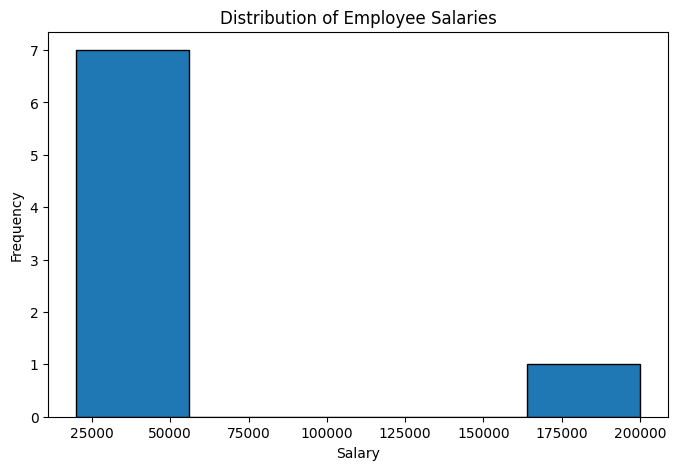

In [24]:
# Create a histogram of employee salaries

plt.figure(figsize=(8, 5))

plt.hist(df["Salary"], bins=5, edgecolor="black")

plt.title("Distribution of Employee Salaries")
plt.xlabel("Salary")
plt.ylabel("Frequency")

plt.show()

In [25]:
# Statistical summary of the dataset

df["Salary"].describe()

count         8.000000
mean      55625.000000
std       59187.203009
min       20000.000000
25%       28750.000000
50%       37500.000000
75%       46250.000000
max      200000.000000
Name: Salary, dtype: float64

## 7. Box Plot

### 1. What is a Box Plot?

A box plot is a graphical representation of numerical data. It shows the distribution, median, quartiles, and potential outliers.

### 2. Main Components of a Box Plot

1. **Minimum:** The smallest non-outlier value.
2. **Q1:** The first quartile (25th percentile).
3. **Median:** The middle value (50th percentile).
4. **Q3:** The third quartile (75th percentile).
5. **Maximum:** The largest non-outlier value.
6. **Outliers:** Values that appear separately from the main distribution.

### 3. Importance in Data Analytics

- Helps identify potential outliers.
- Shows the spread of numerical data.
- Helps compare distributions.
- Makes it easier to understand quartiles and median visually.

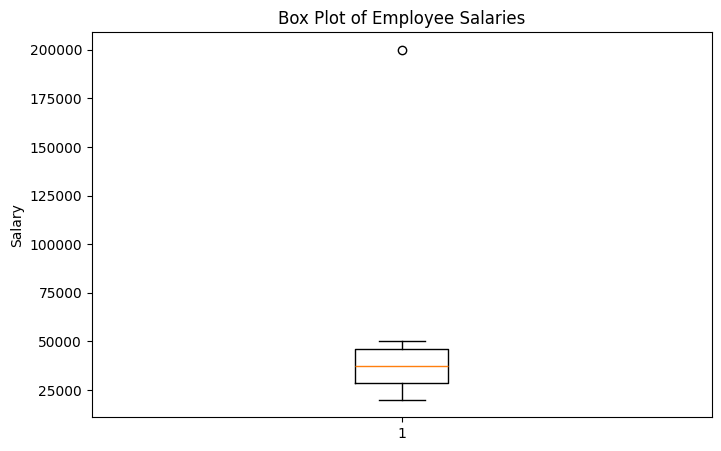

In [26]:
# Create a box plot of employee salaries

plt.figure(figsize=(8, 5))

plt.boxplot(df["Salary"])

plt.title("Box Plot of Employee Salaries")
plt.ylabel("Salary")

plt.show()

## 8. Correlation and Its Limitations

### 1. What is Correlation?

Correlation measures the strength and direction of the relationship between two numerical variables.

For example:
- Study hours
- Test scores

We can use correlation to understand whether students who study more hours tend to achieve higher test scores.

### 2. Types of Correlation

**1. Positive Correlation**
- Both variables move in the same direction.
- When one variable increases, the other tends to increase.
- Example: Study hours and test scores.

**2. Negative Correlation**
- Variables move in opposite directions.
- When one variable increases, the other tends to decrease.
- Example: Product price and demand (in some situations).

**3. Zero or No Linear Correlation**
- There is no clear linear relationship between the two variables.

### 3. Correlation Coefficient

The correlation coefficient ranges from -1 to +1.

- +1: Perfect positive correlation.
- -1: Perfect negative correlation.
- 0: No linear correlation.

### 4. Limitations of Correlation

1. Correlation does not prove causation.
2. Outliers can affect correlation.
3. Correlation measures linear relationships when using Pearson's correlation.
4. Two variables may be correlated without having a direct relationship.

**Importance in Data Analytics:** Correlation helps analysts identify relationships and patterns between numerical variables.

In [27]:
# Calculate correlation between numerical columns

correlation = df.corr()

print("Correlation Matrix:")
correlation

Correlation Matrix:


,Salary,Study_Hours,Test_Score
Salary,1.000000,0.707002,0.815662
Study_Hours,0.707002,1.000000,0.981644
Test_Score,0.815662,0.981644,1.000000


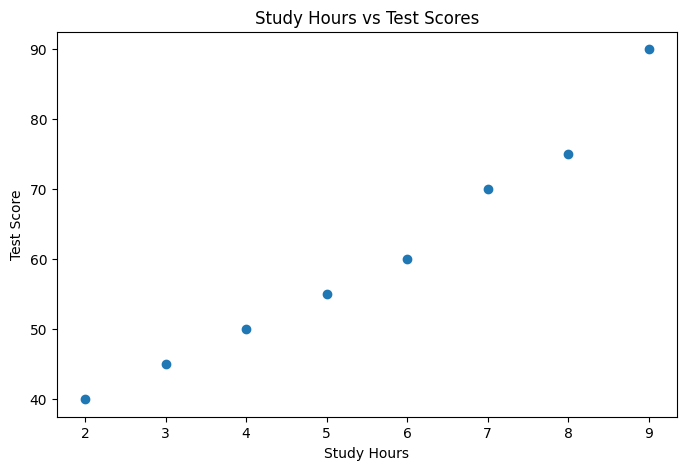

In [28]:
# Create a scatter plot

plt.figure(figsize=(8, 5))

plt.scatter(df["Study_Hours"], df["Test_Score"])

plt.title("Study Hours vs Test Scores")
plt.xlabel("Study Hours")
plt.ylabel("Test Score")

plt.show()

## 8. Correlation and Its Limitations

### 1. What is Correlation?

Correlation measures the strength and direction of the relationship between two numerical variables.

For example:
- Study hours
- Test scores

We can use correlation to understand whether students who study more hours tend to achieve higher test scores.

### 2. Types of Correlation

**1. Positive Correlation**
- Both variables move in the same direction.
- When one variable increases, the other tends to increase.
- Example: Study hours and test scores.

**2. Negative Correlation**
- Variables move in opposite directions.
- When one variable increases, the other tends to decrease.
- Example: Product price and demand (in some situations).

**3. Zero or No Linear Correlation**
- There is no clear linear relationship between the two variables.

### 3. Correlation Coefficient

The correlation coefficient ranges from -1 to +1.

- +1: Perfect positive correlation.
- -1: Perfect negative correlation.
- 0: No linear correlation.

### 4. Limitations of Correlation

1. Correlation does not prove causation.
2. Outliers can affect correlation.
3. Correlation measures linear relationships when using Pearson's correlation.
4. Two variables may be correlated without having a direct relationship.

**Importance in Data Analytics:** Correlation helps analysts identify relationships and patterns between numerical variables.

In [29]:
# Calculate correlation between numerical columns

correlation = df.corr()

print("Correlation Matrix:")
correlation

Correlation Matrix:


,Salary,Study_Hours,Test_Score
Salary,1.000000,0.707002,0.815662
Study_Hours,0.707002,1.000000,0.981644
Test_Score,0.815662,0.981644,1.000000


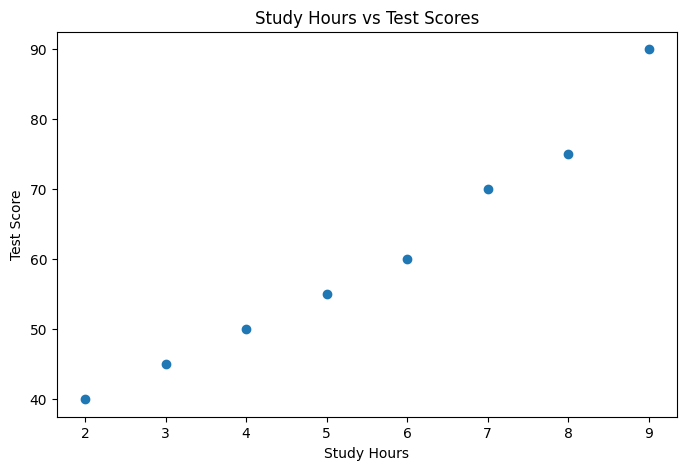

In [30]:
# Create a scatter plot

plt.figure(figsize=(8, 5))

plt.scatter(df["Study_Hours"], df["Test_Score"])

plt.title("Study Hours vs Test Scores")
plt.xlabel("Study Hours")
plt.ylabel("Test Score")

plt.show()

In [31]:
# Compare mean and median with and without the outlier

salary_with_outlier = df["Salary"]

# Remove the potential outlier for demonstration
salary_without_outlier = salary_with_outlier[
    salary_with_outlier <= upper_limit
]

# Calculate mean and median

comparison = pd.DataFrame({
    "Measure": ["Mean", "Median"],
    "With Outlier": [
        salary_with_outlier.mean(),
        salary_with_outlier.median()
    ],
    "Without Outlier": [
        salary_without_outlier.mean(),
        salary_without_outlier.median()
    ]
})

comparison

,Measure,With Outlier,Without Outlier
0,Mean,55625.0,35000.0
1,Median,37500.0,35000.0


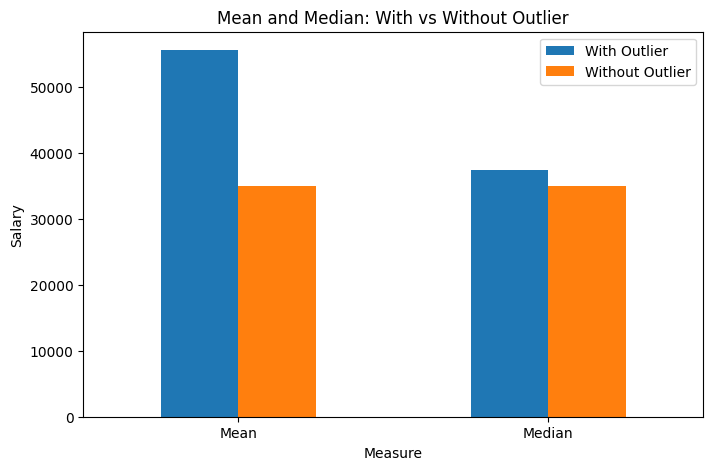

In [32]:
# Visual comparison

comparison.set_index("Measure").plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Mean and Median: With vs Without Outlier")
plt.ylabel("Salary")
plt.xticks(rotation=0)

plt.show()

# Day 11 — Probability Fundamentals

## 1. Introduction to Probability

### What is Probability?

Probability is the measure of how likely an event is to happen.

It tells us the possibility of an event occurring.

### Probability Formula

Probability = Number of Favorable Outcomes / Total Number of Possible Outcomes

### Example

Suppose we have a fair coin.

A coin has two possible outcomes:

- Heads
- Tails

The probability of getting Heads is:

P(Heads) = 1 / 2 = 0.5 or 50%

The probability of getting Tails is also:

P(Tails) = 1 / 2 = 0.5 or 50%

### Probability Values

Probability always ranges from 0 to 1.

- 0 means the event is impossible.
- 0.5 means the event has a 50% chance.
- 1 means the event is certain.

### Importance in Data Analytics

Probability helps data analysts understand uncertainty, estimate the likelihood of events, analyse risks, and make informed decisions.

In [33]:
# Basic Probability Calculation

total_outcomes = 2
favorable_outcomes = 1

probability_heads = favorable_outcomes / total_outcomes

print("Probability of getting Heads:", probability_heads)
print("Probability in Percentage:", probability_heads * 100, "%")

Probability of getting Heads: 0.5
Probability in Percentage: 50.0 %
